# 01 Data profile and V-column pruning proposal

Step 2. Logic lives in `src/data_profile.py`; this notebook runs it and shows the results. Everything is computed on the training block (first 80% by time).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_joined
from src import data_profile as dp

train = dp.train_block(load_joined())
prof = dp.column_profile(train)
print(train.shape, f"fraud rate {train['isFraud'].mean():.4f}")

(472432, 436) fraud rate 0.0351


## Missingness and fraud rate, most-missing columns first

In [2]:
pd.set_option('display.width', 160)
prof.head(25)

,column,dtype,pct_missing,n_distinct,fraud_rate_missing,fraud_rate_present
0,id_24,float32,99.171521,11,0.034756,0.080480
1,id_25,float32,99.101246,317,0.034745,0.078191
2,id_07,float32,99.098071,82,0.034742,0.078385
3,id_08,float32,99.098071,93,0.034742,0.078385
4,id_21,float32,99.097648,444,0.034742,0.078349
5,id_26,float32,99.096801,89,0.034744,0.078041
6,id_22,float32,99.095531,23,0.034742,0.078165
7,id_23,category,99.095531,3,0.034742,0.078165
8,id_27,category,99.095531,2,0.034742,0.078165
9,D7,float32,93.661733,568,0.027384,0.149679


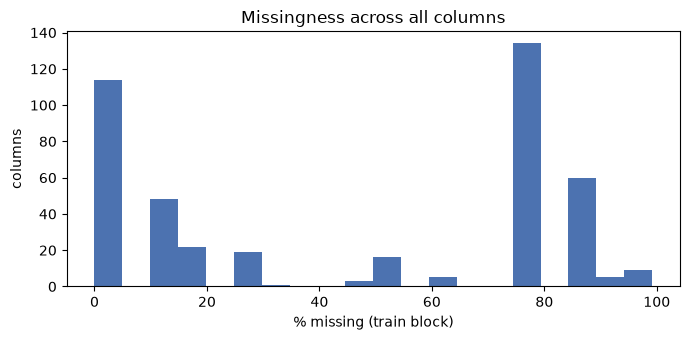

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(prof['pct_missing'], bins=20, color='#4c72b0')
ax.set_xlabel('% missing (train block)'); ax.set_ylabel('columns'); ax.set_title('Missingness across all columns')
plt.tight_layout(); plt.show()

## Does missingness carry signal?
Columns with at least 1% missing and 1% present, ranked by fraud rate when missing divided by fraud rate when present.

In [4]:
m = prof[(prof.pct_missing.between(1, 99))].copy()
m['ratio'] = m.fraud_rate_missing / m.fraud_rate_present
m.sort_values('ratio', ascending=False).head(15)[['column', 'pct_missing', 'fraud_rate_missing', 'fraud_rate_present', 'ratio']]

,column,pct_missing,fraud_rate_missing,fraud_rate_present,ratio
321,addr2,11.379627,0.113986,0.025010,4.557599
320,addr1,11.379627,0.113986,0.025010,4.557599
232,M6,29.933408,0.068338,0.020951,3.261860
226,M1,50.440063,0.049959,0.020048,2.491962
227,M2,50.440063,0.049959,0.020048,2.491962
228,M3,50.440063,0.049959,0.020048,2.491962
219,V5,52.065271,0.049253,0.019800,2.487482
223,V9,52.065271,0.049253,0.019800,2.487482
222,V8,52.065271,0.049253,0.019800,2.487482
221,V7,52.065271,0.049253,0.019800,2.487482


## V-column groups and pruning proposal

In [5]:
proposal = dp.v_proposal(train)
pd.DataFrame([{k: (len(v) if isinstance(v, list) else v) for k, v in g.items() if k != 'because'} for g in proposal])

,group,n_missing,pct_missing,columns,keep,drop,same_mask
0,1,12,0.002540,32,24,8,True
1,2,97,0.020532,43,39,4,True
2,3,936,0.198124,11,9,2,True
3,4,66427,14.060648,23,11,12,True
4,5,66890,14.158651,22,12,10,True
5,6,77793,16.466497,20,13,7,True
6,7,139809,29.593465,18,12,6,True
7,8,245973,52.065271,11,9,2,True
8,9,354412,75.018627,16,8,8,True
9,10,355767,75.305441,19,15,4,True


In [6]:
print('keep', sum(len(g['keep']) for g in proposal), 'drop', sum(len(g['drop']) for g in proposal))

keep 229 drop 110


Writing the report and `config/features.yaml` is done by `python -m src.data_profile`.